<a href="https://colab.research.google.com/github/Chathuranga630/sionna/blob/main/Sionna_test_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# STEP 1 — Install (run in terminal, not inside this script):
#   python -m venv .venv
#   Windows: .venv\Scripts\activate
#   python -m pip install --upgrade pip
#   python -m pip install numpy pandas matplotlib scipy torch sionna
#   python -m pip install jupyter
# Sionna 2.x requires a compatible PyTorch environment. See official installation:
# https://nvlabs.github.io/sionna/installation.html
!pip install sionna

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cpu
Sionna: 2.2.0
Compute device: cpu


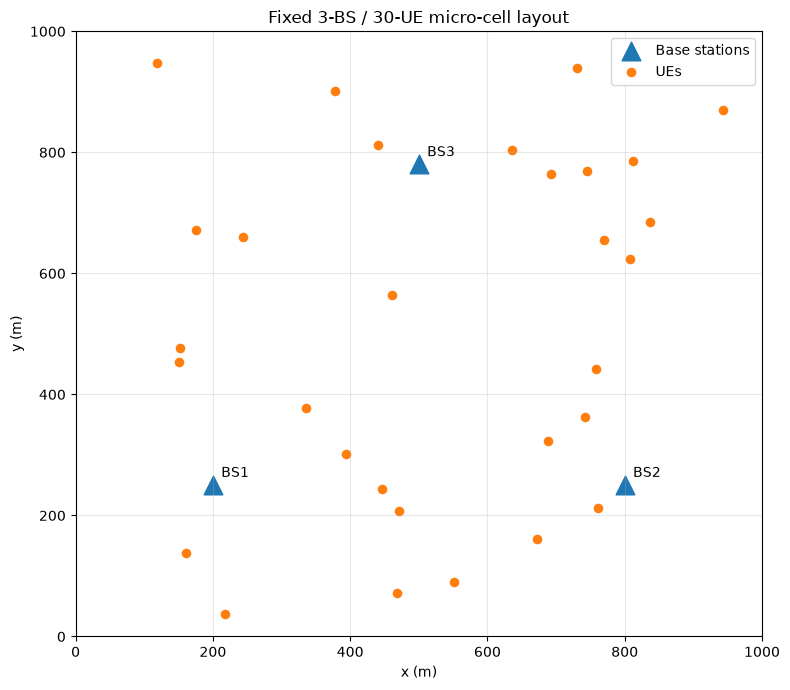

Baseline UE counts: [10  9 11]

QoS summary (system-level estimates):
           scenario               stage  total_throughput_est_mbps  mean_latency_est_ms  mean_packet_loss_est  mean_PDR_est  mean_SINR_dB  mean_BS_utilization  UEs_reassigned
 High attack (100%)  After reassignment                    134.821               97.706                   0.0           1.0         4.831                0.466               6
 High attack (100%) Before reassignment                    140.000              393.000                   0.0           1.0         6.009                0.489               6
   Low attack (25%)  After reassignment                    105.500               64.206                   0.0           1.0         4.746                0.352               6
   Low attack (25%) Before reassignment                    105.500               79.608                   0.0           1.0         6.009                0.363               6
Medium attack (50%)  After reassignment                

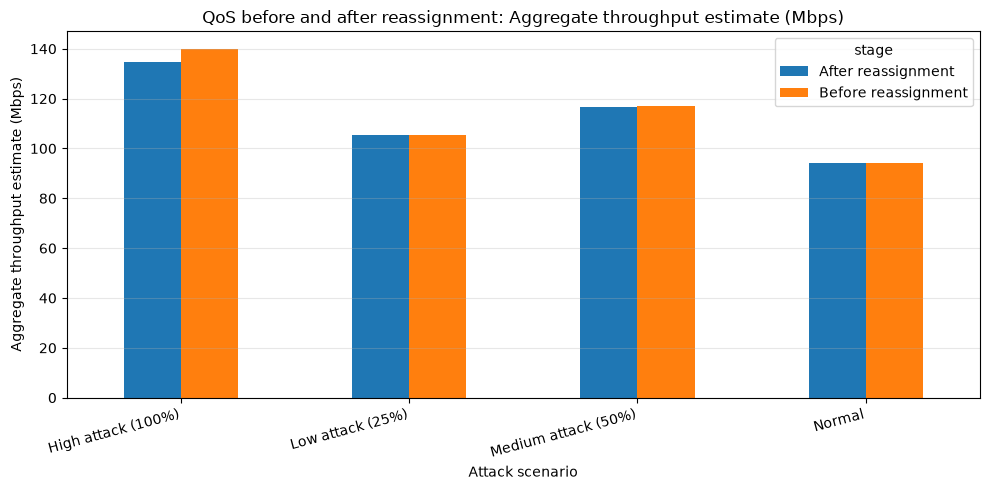

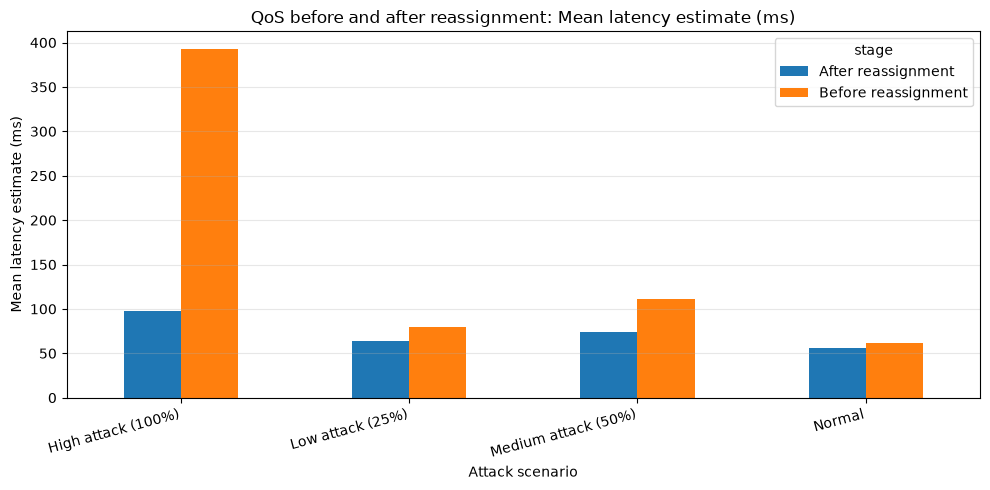

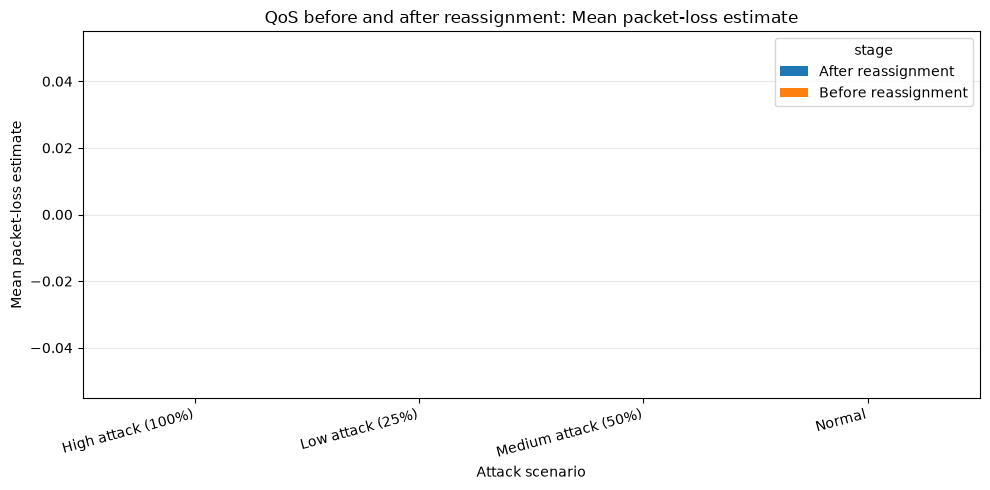

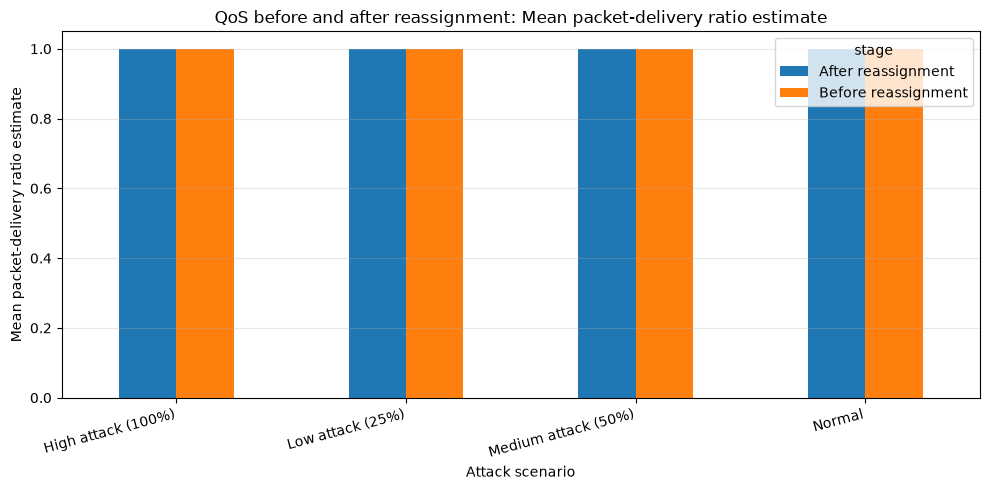

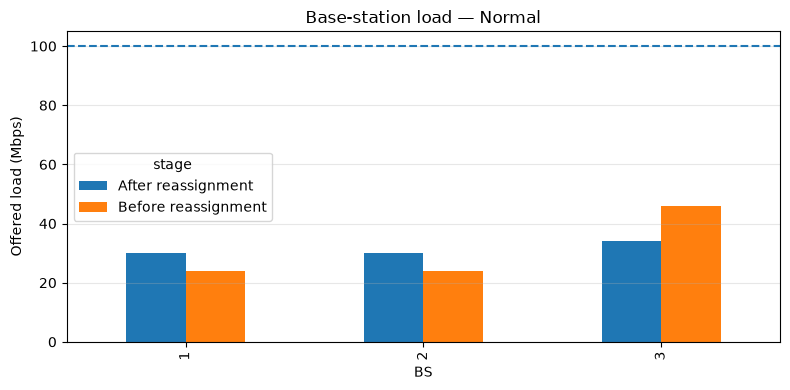

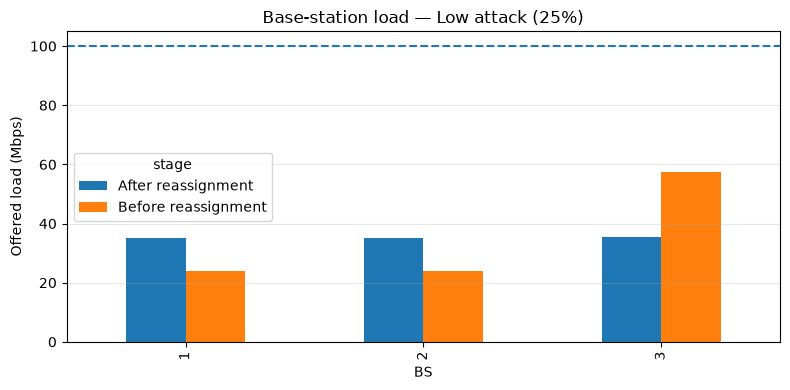

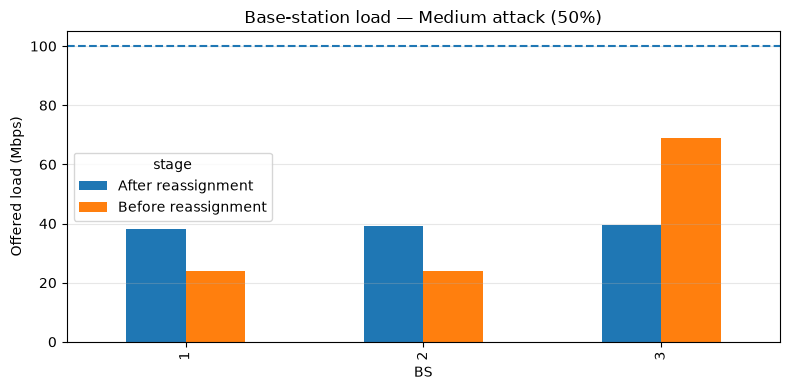

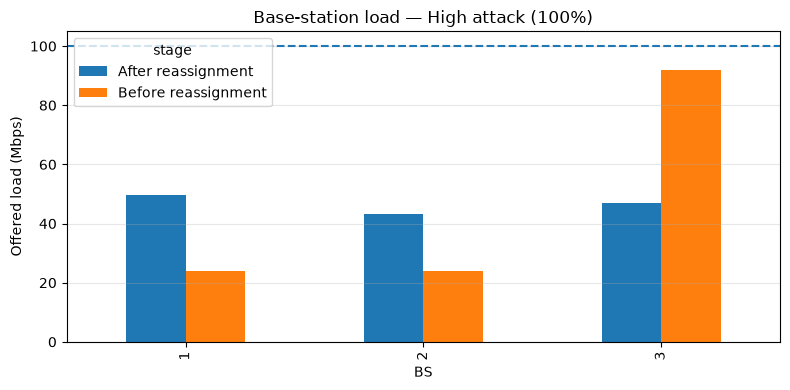


STEP 18 — QoS Before and After User Reassignment
           scenario  throughput_before_mbps_est  throughput_after_mbps_est  latency_before_ms_est  latency_after_ms_est  packet_loss_before_est  packet_loss_after_est  PDR_before_est  PDR_after_est  UEs_reassigned
             Normal                        94.0                    94.0000                61.2346               55.4545                     0.0                    0.0             1.0            1.0               4
   Low attack (25%)                       105.5                   105.5000                79.6078               64.2060                     0.0                    0.0             1.0            1.0               6
Medium attack (50%)                       117.0                   116.7159               111.6129               73.6537                     0.0                    0.0             1.0            1.0               6
 High attack (100%)                       140.0                   134.8210               393.0

In [2]:
"""
Research project:
Impact Assessment of Spoofed Traffic Attacks on User Assignment and QoS
in Micro-cell Networks Using Sionna

18-step reproducible baseline.
Important scope note:
- The multi-cell network/attack/reassignment/QoS portion is a SYSTEM-LEVEL model.
- The included Sionna UMi channel hook is a 3GPP channel-model integration point.
- This file does NOT claim decoded 5G NR packet-level throughput unless the optional
  Sionna PHY link simulation is separately implemented and validated.
- Do not report analytical throughput/latency as measured 5G PHY measurements.
"""

# STEP 2 — Imports and reproducibility
import sys
import platform
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

OUT = Path("spoofed_traffic_results")
OUT.mkdir(parents=True, exist_ok=True)

# STEP 3 — Verify Python, PyTorch, and Sionna
print("Python:", sys.version)
print("Platform:", platform.platform())
try:
    import torch
    import sionna
    print("PyTorch:", torch.__version__)
    print("Sionna:", getattr(sionna, "__version__", "version attribute unavailable"))
    print("Compute device:", "cuda" if torch.cuda.is_available() else "cpu")
except ImportError as exc:
    raise SystemExit(
        "Required package missing. Activate your project environment and run:\n"
        "python -m pip install numpy pandas matplotlib scipy torch sionna\n"
        f"Original import error: {exc}"
    )

# STEP 4 — Project parameters (edit only here for controlled experiments)
AREA_M = 1000.0
NUM_BS = 3
NUM_UE = 30
BS_CAPACITY_MBPS = 100.0      # network-level capacity assumption per BS
CARRIER_HZ = 3.5e9
BANDWIDTH_HZ = 20e6
NOISE_DENSITY_DBM_HZ = -174.0
UE_TX_POWER_DBM = 23.0
BS_HEIGHT_M = 10.0
UE_HEIGHT_M = 1.5
SCENARIOS = {
    "Normal": 0.00,
    "Low attack (25%)": 0.25,
    "Medium attack (50%)": 0.50,
    "High attack (100%)": 1.00,
}
PACKET_SIZE_BITS = 12000       # illustrative 1500-byte IP packet
SIM_TIME_S = 10.0
PACKET_INTERVAL_S = 0.02       # 50 packets/s per UE baseline
MAX_LATENCY_MS = 1000.0        # cap for reporting; identify capped values

# STEP 5 — Create fixed micro-cell layout and fixed UE locations
bs_xy = np.array([
    [200.0, 250.0],
    [800.0, 250.0],
    [500.0, 780.0],
])
ue_xy = rng.uniform(30.0, AREA_M - 30.0, size=(NUM_UE, 2))
bs_xyz = np.column_stack([bs_xy, np.full(NUM_BS, BS_HEIGHT_M)])
ue_xyz = np.column_stack([ue_xy, np.full(NUM_UE, UE_HEIGHT_M)])
np.save(OUT / "fixed_ue_positions.npy", ue_xyz)
np.save(OUT / "base_station_positions.npy", bs_xyz)

# STEP 6 — Plot network layout
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(bs_xy[:, 0], bs_xy[:, 1], marker="^", s=180, label="Base stations")
ax.scatter(ue_xy[:, 0], ue_xy[:, 1], marker="o", s=35, label="UEs")
for i, (x, y) in enumerate(bs_xy):
    ax.annotate(f"BS{i+1}", (x, y), xytext=(6, 6), textcoords="offset points")
ax.set(xlim=(0, AREA_M), ylim=(0, AREA_M), xlabel="x (m)", ylabel="y (m)",
       title="Fixed 3-BS / 30-UE micro-cell layout")
ax.grid(True, alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(OUT / "01_network_layout.png", dpi=180); plt.show()

# STEP 7 — Distances, path loss, and small-scale fading
# UMi-like simplified path-loss baseline for network association.
# This is not a substitute for Sionna's full TR 38.901 UMi channel coefficients.
dist_m = np.maximum(
    np.linalg.norm(ue_xy[:, None, :] - bs_xy[None, :, :], axis=2), 10.0
)
dist_3d_m = np.sqrt(dist_m**2 + (BS_HEIGHT_M - UE_HEIGHT_M)**2)
fc_ghz = CARRIER_HZ / 1e9
# Simplified LOS-like path loss; used only for preliminary system-level ranking.
path_loss_db = 32.4 + 21.0*np.log10(dist_3d_m) + 20.0*np.log10(fc_ghz)
# Rayleigh power fading, normalized to unit mean. Same realization for all scenarios.
rayleigh_power = rng.exponential(scale=1.0, size=(NUM_UE, NUM_BS))
shadowing_db = rng.normal(0.0, 4.0, size=(NUM_UE, NUM_BS))
rx_power_dbm = UE_TX_POWER_DBM - path_loss_db + shadowing_db + 10*np.log10(
    np.maximum(rayleigh_power, 1e-12)
)
np.save(OUT / "received_power_dbm.npy", rx_power_dbm)

# STEP 8 — SINR matrix
noise_dbm = NOISE_DENSITY_DBM_HZ + 10*np.log10(BANDWIDTH_HZ)
# Received signal power in mW
rx_mw = 10**(rx_power_dbm/10.0)
noise_mw = 10**(noise_dbm/10.0)
sinr_linear = np.zeros_like(rx_mw)
for u in range(NUM_UE):
    for b in range(NUM_BS):
        interference = rx_mw[u, :].sum() - rx_mw[u, b]
        sinr_linear[u, b] = rx_mw[u, b] / (noise_mw + interference)
sinr_db = 10*np.log10(np.maximum(sinr_linear, 1e-12))
pd.DataFrame(sinr_db, columns=[f"BS{i+1}" for i in range(NUM_BS)]).to_csv(
    OUT / "sinr_matrix_db.csv", index_label="UE"
)

# STEP 9 — Baseline strongest-signal user assignment
initial_assignment = np.argmax(rx_power_dbm, axis=1)
initial_assignment_saved = initial_assignment.copy()
assert len(initial_assignment) == NUM_UE
print("Baseline UE counts:", np.bincount(initial_assignment, minlength=NUM_BS))

# STEP 10 — Generate legitimate user traffic
# Heterogeneous but fixed offered load per UE; identical for all attack scenarios.
traffic_mbps = rng.choice([1.0, 2.0, 4.0, 6.0, 8.0], size=NUM_UE,
                          p=[0.15, 0.25, 0.30, 0.20, 0.10])
traffic_mbps = traffic_mbps.astype(float)
traffic_df = pd.DataFrame({
    "UE": np.arange(NUM_UE), "traffic_mbps": traffic_mbps,
    "initial_BS": initial_assignment + 1,
    "best_SINR_dB": sinr_db[np.arange(NUM_UE), initial_assignment]
})
traffic_df.to_csv(OUT / "ue_traffic_and_assignment.csv", index=False)

# STEP 11 — Add spoofed traffic to targeted BSs
# Spoofed traffic is modeled as extra offered load at the currently most-loaded BS.
def make_offered_load(attack_fraction):
    offered = traffic_mbps.copy()
    if attack_fraction <= 0:
        return offered, np.zeros(NUM_UE)
    base_load = np.bincount(initial_assignment, weights=traffic_mbps,
                            minlength=NUM_BS)
    target_bs = int(np.argmax(base_load))
    legitimate_at_target = initial_assignment == target_bs
    # Additional malicious demand equals attack_fraction times the legitimate
    # traffic aggregated at the target BS, distributed over its attached UEs.
    malicious_total = attack_fraction * base_load[target_bs]
    weights = np.ones(legitimate_at_target.sum())
    if weights.size:
        offered[legitimate_at_target] += malicious_total / weights.size
    spoofed = np.zeros(NUM_UE)
    if weights.size:
        spoofed[legitimate_at_target] = malicious_total / weights.size
    return offered, spoofed

# STEP 12 — Load-aware user reassignment
# Move a UE only when a different BS has adequate radio quality and lower normalized
# projected load. The method is deterministic for a given channel/traffic realization.
def reassign_users(offered_mbps, starting_assignment):
    assignment = starting_assignment.copy()
    for _ in range(NUM_UE * 3):
        loads = np.bincount(assignment, weights=offered_mbps, minlength=NUM_BS)
        util = loads / BS_CAPACITY_MBPS
        changed = False
        # Evaluate highest-demand UEs first
        for u in np.argsort(offered_mbps)[::-1]:
            old = assignment[u]
            candidates = np.argsort(-sinr_db[u])
            # Candidate BS must be no more than 8 dB below the best BS's SINR.
            best_sinr = np.max(sinr_db[u])
            valid = [int(b) for b in candidates if sinr_db[u, b] >= best_sinr - 8.0]
            if not valid:
                continue
            best = min(valid, key=lambda b: util[b])
            if best != old and util[best] + offered_mbps[u]/BS_CAPACITY_MBPS < util[old]:
                assignment[u] = best
                changed = True
                break
        if not changed:
            break
    return assignment

# STEP 13 — System-level QoS estimator
# Clearly labeled estimates, not decoded packet-level measurements.
def calculate_qos(assignment, offered_mbps, spoofed_mbps):
    bs_load = np.bincount(assignment, weights=offered_mbps, minlength=NUM_BS)
    util = bs_load / BS_CAPACITY_MBPS
    rows = []
    for u in range(NUM_UE):
        b = int(assignment[u])
        radio_eff = np.log2(1.0 + max(sinr_linear[u, b], 1e-12))
        radio_capacity = BANDWIDTH_HZ * radio_eff / 1e6
        # Allocate a fair share of the nominal BS capacity among its offered load.
        if bs_load[b] <= 0:
            delivered = 0.0
        else:
            share = min(1.0, BS_CAPACITY_MBPS / bs_load[b])
            delivered = min(offered_mbps[u] * share, radio_capacity)
        overload = max(0.0, bs_load[b] - BS_CAPACITY_MBPS)
        # Congestion loss approximation; bounded [0,1].
        packet_loss = min(0.99, max(0.0, overload / max(bs_load[b], 1e-9)))
        # Delay approximation; explicitly a model assumption, not PHY measured latency.
        latency_ms = 10.0 + 100.0 * util[b] / max(1.0 - min(util[b], 0.99), 0.01)
        latency_ms = min(latency_ms, MAX_LATENCY_MS)
        pdr = 1.0 - packet_loss
        rows.append({
            "UE": u, "BS": b+1, "offered_mbps": offered_mbps[u],
            "spoofed_mbps": spoofed_mbps[u], "throughput_est_mbps": delivered,
            "latency_est_ms": latency_ms, "packet_loss_est": packet_loss,
            "PDR_est": pdr, "SINR_dB": sinr_db[u, b],
            "BS_load_mbps": bs_load[b], "BS_utilization": util[b],
            "latency_capped": latency_ms >= MAX_LATENCY_MS
        })
    return pd.DataFrame(rows), bs_load, util

# STEP 14 — Execute all attack scenarios, preserving UE positions and channel realization
all_user_results = []
all_bs_results = []
scenario_assignments = {}
for scenario_name, attack_fraction in SCENARIOS.items():
    offered, spoofed = make_offered_load(attack_fraction)
    assignment_before = initial_assignment_saved.copy()
    assignment_after = reassign_users(offered, assignment_before)
    scenario_assignments[scenario_name] = assignment_after.copy()

    before_df, before_load, before_util = calculate_qos(
        assignment_before, offered, spoofed
    )
    before_df["scenario"] = scenario_name
    before_df["stage"] = "Before reassignment"
    after_df, after_load, after_util = calculate_qos(
        assignment_after, offered, spoofed
    )
    after_df["scenario"] = scenario_name
    after_df["stage"] = "After reassignment"
    all_user_results.extend([before_df, after_df])

    for stage, load, util in [
        ("Before reassignment", before_load, before_util),
        ("After reassignment", after_load, after_util)
    ]:
        for b in range(NUM_BS):
            all_bs_results.append({
                "scenario": scenario_name, "stage": stage, "BS": b+1,
                "offered_load_mbps": load[b],
                "capacity_mbps": BS_CAPACITY_MBPS,
                "utilization": util[b], "over_capacity": load[b] > BS_CAPACITY_MBPS
            })

user_results = pd.concat(all_user_results, ignore_index=True)
bs_results = pd.DataFrame(all_bs_results)
user_results.to_csv(OUT / "ue_qos_before_after.csv", index=False)
bs_results.to_csv(OUT / "bs_load_before_after.csv", index=False)

# STEP 15 — Summarize network QoS
summary = (user_results.groupby(["scenario", "stage"], as_index=False)
           .agg(total_throughput_est_mbps=("throughput_est_mbps", "sum"),
                mean_latency_est_ms=("latency_est_ms", "mean"),
                mean_packet_loss_est=("packet_loss_est", "mean"),
                mean_PDR_est=("PDR_est", "mean"),
                mean_SINR_dB=("SINR_dB", "mean"),
                mean_BS_utilization=("BS_utilization", "mean"),
                reassigned_UE_count=("BS", "nunique")))
# Correct reassignment count as a separate per-scenario metric.
move_counts = []
for name, attack_fraction in SCENARIOS.items():
    offered, spoofed = make_offered_load(attack_fraction)
    new_assignment = scenario_assignments[name]
    move_counts.append({"scenario": name,
                        "UEs_reassigned": int(np.sum(new_assignment != initial_assignment_saved))})
moves_df = pd.DataFrame(move_counts)
summary = summary.drop(columns=["reassigned_UE_count"]).merge(moves_df, on="scenario")
summary.to_csv(OUT / "scenario_qos_summary.csv", index=False)
print("\nQoS summary (system-level estimates):")
print(summary.round(3).to_string(index=False))

# STEP 16 — Plot before/after QoS for each attack scenario
metrics = [
    ("total_throughput_est_mbps", "Aggregate throughput estimate (Mbps)"),
    ("mean_latency_est_ms", "Mean latency estimate (ms)"),
    ("mean_packet_loss_est", "Mean packet-loss estimate"),
    ("mean_PDR_est", "Mean packet-delivery ratio estimate"),
]
for col, ylabel in metrics:
    pivot = summary.pivot(index="scenario", columns="stage", values=col)
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_ylabel(ylabel); ax.set_xlabel("Attack scenario")
    ax.set_title(f"QoS before and after reassignment: {ylabel}")
    ax.grid(axis="y", alpha=.3); plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    fname = col.replace("/", "_")
    plt.savefig(OUT / f"qos_{fname}.png", dpi=180)
    plt.show()

# STEP 17 — Plot base-station loads and assignment changes
for scenario_name in SCENARIOS:
    subset = bs_results[bs_results["scenario"] == scenario_name]
    pivot = subset.pivot(index="BS", columns="stage", values="offered_load_mbps")
    ax = pivot.plot(kind="bar", figsize=(8, 4))
    ax.axhline(BS_CAPACITY_MBPS, linestyle="--", label="Capacity (100 Mbps)")
    ax.set_ylabel("Offered load (Mbps)")
    ax.set_title(f"Base-station load — {scenario_name}")
    ax.grid(axis="y", alpha=.3); plt.tight_layout()
    plt.savefig(OUT / f"bs_load_{scenario_name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('%','pct')}.png", dpi=180)
    plt.show()

# STEP 18 — QoS before/after reassignment table and validation exports
before = summary[summary["stage"] == "Before reassignment"].set_index("scenario")
after = summary[summary["stage"] == "After reassignment"].set_index("scenario")
comparison_rows = []
for name in SCENARIOS:
    b, a = before.loc[name], after.loc[name]
    comparison_rows.append({
        "scenario": name,
        "throughput_before_mbps_est": b["total_throughput_est_mbps"],
        "throughput_after_mbps_est": a["total_throughput_est_mbps"],
        "latency_before_ms_est": b["mean_latency_est_ms"],
        "latency_after_ms_est": a["mean_latency_est_ms"],
        "packet_loss_before_est": b["mean_packet_loss_est"],
        "packet_loss_after_est": a["mean_packet_loss_est"],
        "PDR_before_est": b["mean_PDR_est"],
        "PDR_after_est": a["mean_PDR_est"],
        "UEs_reassigned": int(a["UEs_reassigned"])
    })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(OUT / "step18_qos_before_after_reassignment.csv", index=False)
print("\nSTEP 18 — QoS Before and After User Reassignment")
print(comparison.round(4).to_string(index=False))

# STEP 19 is intentionally not added: the requested workflow ends at Step 18.
# Optional Sionna 3GPP UMi integration:
# See the official example/API and adapt it to your installed exact Sionna version:
# https://nvlabs.github.io/sionna/phy/api/channel/wireless/3gpp.html
# A complete packet-level 5G NR extension must use PUSCH/ PDSCH transmitter,
# OFDM channel, receiver/decoder and BLER/PDR measurements. These system-level
# estimates must not be relabeled as those measurements.

print(f"\nFinished. Outputs saved to: {OUT.resolve()}")
print("UE coordinates were fixed and reused across all scenarios.")
print("Research integrity note: latency, packet loss and throughput here are model estimates.")
